In [8]:
from aml_working_paper.routing.routing_investigate import build_candidate_windows, select_investigations, validate_investigations
from aml_working_paper.routing.routing import extract_posterior_draws, filter_posterior_draws, build_routing_dataframe
import arviz as az
from aml_working_paper.data.preprocess import preprocess_data
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
import pandas as pd
import numpy as np

In [9]:
df_aml = pd.read_csv("/workspaces/aml-working-paper/data/raw/synthetic_df_aml.csv")
aligned_trace = az.from_netcdf("/workspaces/aml-working-paper/models/bayesian_hmm_aligned_trace.nc")

In [10]:
train_df, val_df, test_df, train_sequences, val_sequences, test_sequences, scaler = preprocess_data(df_aml)

In [13]:
aligned_trace.posterior

<xarray.DataTree 'posterior'>
Group: /posterior
    Dimensions:      (chain: 4, draw: 500, mu_dim_0: 3, mu_dim_1: 3, pi_dim_0: 3,
                      A_dim_0: 3, A_dim_1: 3, sigma_dim_0: 3, sigma_dim_1: 3)
    Coordinates:
      * chain        (chain) int64 32B 0 1 2 3
      * draw         (draw) int64 4kB 0 1 2 3 4 5 6 ... 493 494 495 496 497 498 499
      * mu_dim_0     (mu_dim_0) int64 24B 0 1 2
      * mu_dim_1     (mu_dim_1) int64 24B 0 1 2
      * pi_dim_0     (pi_dim_0) int64 24B 0 1 2
      * A_dim_0      (A_dim_0) int64 24B 0 1 2
      * A_dim_1      (A_dim_1) int64 24B 0 1 2
      * sigma_dim_0  (sigma_dim_0) int64 24B 0 1 2
      * sigma_dim_1  (sigma_dim_1) int64 24B 0 1 2
    Data variables:
        mu           (chain, draw, mu_dim_0, mu_dim_1) float64 144kB ...
        pi           (chain, draw, pi_dim_0) float64 48kB 0.02535 0.8679 ... 0.1549
        A            (chain, draw, A_dim_0, A_dim_1) float64 144kB ...
        sigma        (chain, draw, sigma_dim_0, sigma_dim_1) float64 144kB ...
    Attributes:
        created_at:                 2026-10-07T20:51:14.708586+00:00
        creation_library:           ArviZ
        creation_library_version:   1.3.1
        creation_library_language:  Python
        inference_library:          pymc
        inference_library_version:  6.3.2
        sample_dims:                ['chain', 'draw']
        sampling_time:              358.9475853443146
        tuning_steps:               500

In [11]:
pi_draws, A_draws, mu_draws, sigma_draws = (extract_posterior_draws(aligned_trace))

KeyError: 'Could not find node at current'

In [ ]:
sequence = val_sequences[0]

results = filter_posterior_draws(
    sequence,
    pi_draws,
    A_draws,
    mu_draws,
    sigma_draws,
)

In [ ]:
print(results["filtered_probabilities"].shape)
print(results["uncertainty"].shape)
print(results["surprise"].shape)
print(results["information_gain"].shape)

(100, 3)
(100,)
(100,)
(100,)


In [ ]:
print(
    results["filtered_probabilities"]
    .sum(axis=1)[:10]
)

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [ ]:
print(
    results["uncertainty"].min(),
    results["uncertainty"].max(),
)

0.003954476323777687 0.634135358820992


In [ ]:
print(
    results["parameter_disagreement"].min()
)

9.728403162984414e-06


In [ ]:
account_id = val_df["account_id"].unique()[0]

In [ ]:
probs = results["filtered_probabilities"]

In [ ]:
routing_df = pd.DataFrame({
        "account_id": account_id,
        "time": np.arange(len(probs)),

        "p_state_0": probs[:, 0],
        "p_state_1": probs[:, 1],
        "p_state_2": probs[:, 2],

        "uncertainty": results["uncertainty"],
        "surprise": results["surprise"],
        "information_gain": results["information_gain"],

        "expected_state_entropy":
            results["expected_state_entropy"],

        "parameter_disagreement":
            results["parameter_disagreement"],
    })

In [ ]:
routing_df.head()

,account_id,time,p_state_0,p_state_1,p_state_2,uncertainty,surprise,information_gain,expected_state_entropy,parameter_disagreement
0,12,0,6.767067e-03,0.004866,0.988367,0.064885,3.789641,1.725006,0.062896,0.001989
1,12,1,5.884402e-06,0.832137,0.167857,0.411927,2.074158,1.153489,0.411114,0.000812
2,12,2,4.146509e-06,0.916461,0.083535,0.261580,1.885629,0.103788,0.260779,0.000801
3,12,3,2.820283e-08,0.997142,0.002858,0.017838,0.929809,0.191640,0.017812,0.000026
4,12,4,5.577281e-07,0.978562,0.021437,0.094291,2.317551,0.077412,0.094089,0.000202


In [ ]:
routing_df.to_parquet("/workspaces/aml-working-paper/aml_working_paper/results/routing_df.parquet",index=False)

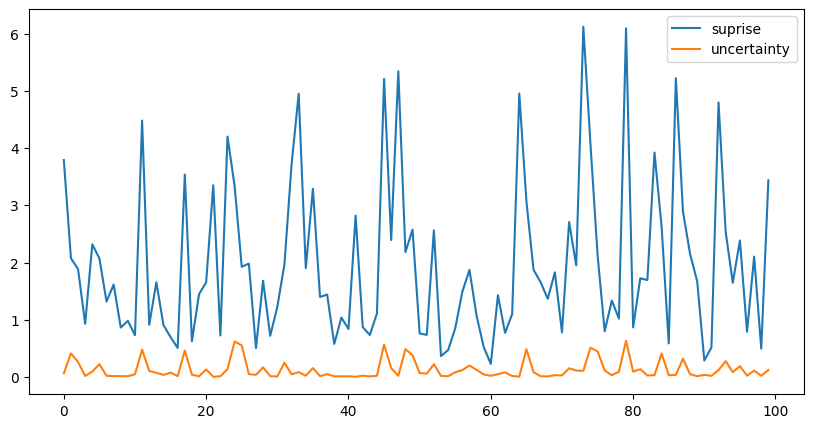

In [ ]:
plt.rcParams["figure.figsize"] = (10, 5)
plt.plot(routing_df["surprise"], label="suprise")
plt.plot(routing_df["uncertainty"], label= "uncertainty")
plt.legend()

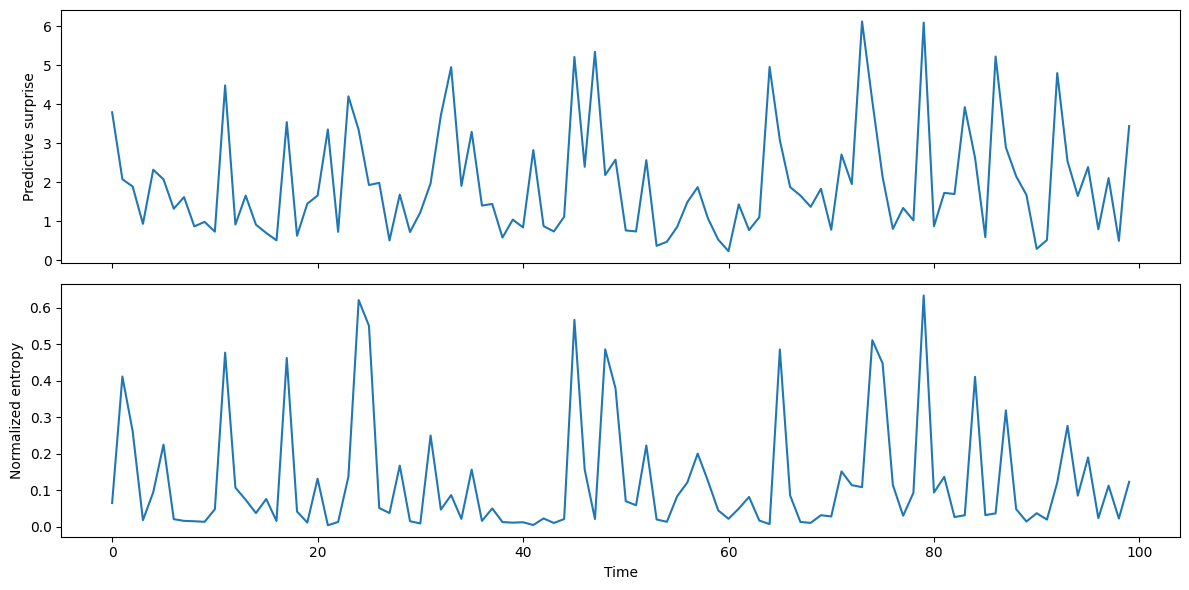

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(routing_df["time"], routing_df["surprise"])
axes[0].set_ylabel("Predictive surprise")

axes[1].plot(routing_df["time"], routing_df["uncertainty"])
axes[1].set_ylabel("Normalized entropy")
axes[1].set_xlabel("Time")

plt.tight_layout()
plt.show()

In [ ]:
account_id = routing_df["account_id"].iloc[0]

truth = (
    val_df[val_df["account_id"] == account_id]
    [["time", "aml_state"]]
    .sort_values("time")
)

comparison = routing_df.merge(
    truth,
    on="time",
    validate="one_to_one",
)

comparison["state_transition"] = (
    comparison["aml_state"]
    .ne(comparison["aml_state"].shift())
)

comparison.loc[comparison.index[0], "state_transition"] = False

In [ ]:
transition_times = comparison.loc[
    comparison["state_transition"],
    "time"
].to_numpy()

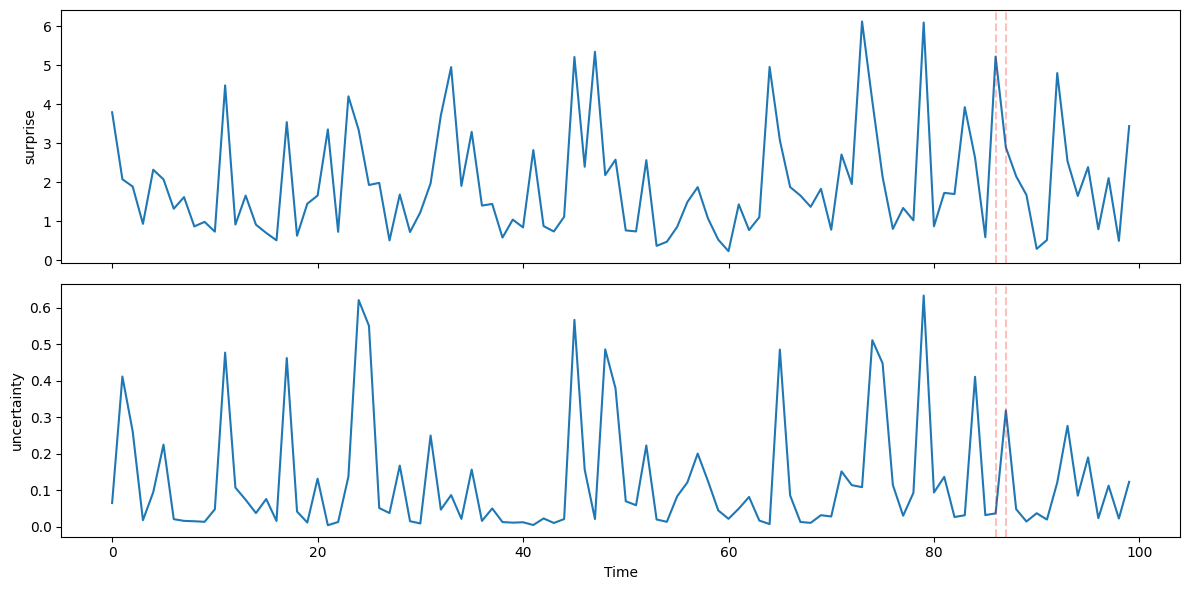

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

for ax, metric in zip(axes, ["surprise", "uncertainty"]):
    ax.plot(comparison["time"], comparison[metric])

    for t in transition_times:
        ax.axvline(t, color="red", alpha=0.25, linestyle="--")

    ax.set_ylabel(metric)

axes[-1].set_xlabel("Time")
plt.tight_layout()
plt.show()

In [ ]:
validation_routing_df = build_routing_dataframe(
    val_df,
    val_sequences,
    pi_draws,
    A_draws,
    mu_draws,
    sigma_draws,
)

print(validation_routing_df.shape)
print(validation_routing_df.head())

(2000, 10)
   account_id  time     p_state_0  p_state_1  p_state_2  uncertainty  \
0          12     0  6.767067e-03   0.004866   0.988367     0.064885   
1          12     1  5.884402e-06   0.832137   0.167857     0.411927   
2          12     2  4.146509e-06   0.916461   0.083535     0.261580   
3          12     3  2.820283e-08   0.997142   0.002858     0.017838   
4          12     4  5.577281e-07   0.978562   0.021437     0.094291   

   surprise  information_gain  expected_state_entropy  parameter_disagreement  
0  3.789641          1.725006                0.062896                0.001989  
1  2.074158          1.153489                0.411114                0.000812  
2  1.885629          0.103788                0.260779                0.000801  
3  0.929809          0.191640                0.017812                0.000026  
4  2.317551          0.077412                0.094089                0.000202  


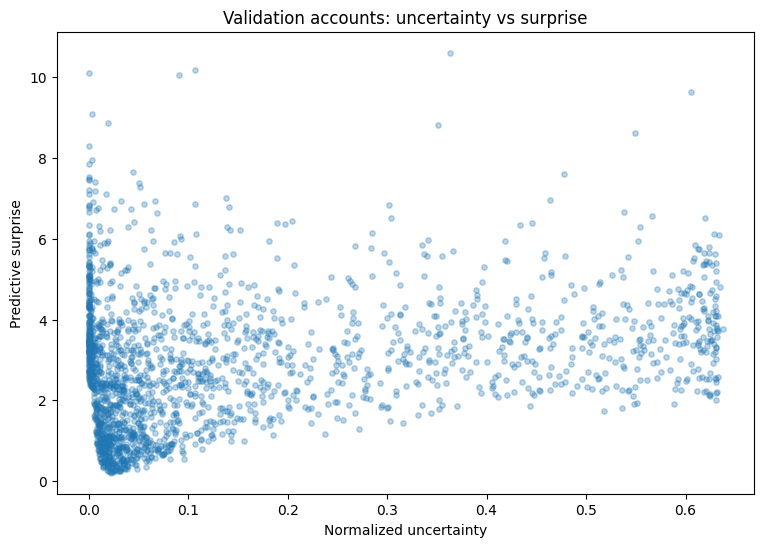

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    validation_routing_df["uncertainty"],
    validation_routing_df["surprise"],
    alpha=0.3,
    s=15,
)

plt.xlabel("Normalized uncertainty")
plt.ylabel("Predictive surprise")
plt.title("Validation accounts: uncertainty vs surprise")

plt.show()

In [ ]:
u = validation_routing_df["uncertainty"]
s = validation_routing_df["surprise"]

print("Pearson:", pearsonr(u, s))
print("Spearman:", spearmanr(u, s))

NameError: name 'validation_routing_df' is not defined

In [ ]:
candidates = build_candidate_windows(
    validation_routing_df,
    window_size=10,
)

print(candidates.shape)
print(candidates.head())

NameError: name 'validation_routing_df' is not defined

In [ ]:
candidates.to_parquet("/workspaces/aml-working-paper/aml_working_paper/data/routing/candidates.parquet", index=False)

In [ ]:
strategies = [
    "uncertainty",
    "surprise",
    "combined",
    "random",
]

selected_windows = {}

for strategy in strategies:

    selected = select_investigations(
        candidates,
        budget=10,
        strategy=strategy,
        random_state=42,
    )

    validate_investigations(
        selected,
        candidates,
        budget=10,
    )

    selected_windows[strategy] = selected

    print(f"\nStrategy: {strategy}")
    print(
        selected[
            [
                "account_id",
                "start_time",
                "end_time",
                "routing_score",
            ]
        ].to_string(index=False)
    )

Investigation selection validated.

Strategy: uncertainty
 account_id  start_time  end_time  routing_score
       55.0        18.0      27.0       0.637370
       70.0         1.0      10.0       0.634174
       12.0        70.0      79.0       0.634135
       53.0        83.0      92.0       0.632833
       33.0        74.0      83.0       0.632629
       33.0        13.0      22.0       0.631808
       30.0        81.0      90.0       0.631763
       40.0         0.0       9.0       0.631440
       15.0        88.0      97.0       0.631200
       44.0        62.0      71.0       0.631074
Investigation selection validated.

Strategy: surprise
 account_id  start_time  end_time  routing_score
       70.0        84.0      93.0      10.604380
       90.0        66.0      75.0      10.166581
       80.0         1.0      10.0      10.110955
       70.0        33.0      42.0      10.041641
       76.0        12.0      21.0       9.639617
       30.0         6.0      15.0       9.080271
     

In [ ]:
def selection_overlap(selected_a, selected_b):
    """
    Number of identical selected windows.
    """

    keys_a = set(
        zip(selected_a["account_id"], selected_a["end_time"])
    )

    keys_b = set(
        zip(selected_b["account_id"], selected_b["end_time"])
    )

    return len(keys_a & keys_b)


for i, strategy_a in enumerate(strategies):

    for strategy_b in strategies[i + 1:]:

        overlap = selection_overlap(
            selected_windows[strategy_a],
            selected_windows[strategy_b],
        )

        print(
            f"{strategy_a} vs {strategy_b}: "
            f"{overlap} identical windows"
        )

uncertainty vs surprise: 0 identical windows
uncertainty vs combined: 1 identical windows
uncertainty vs random: 0 identical windows
surprise vs combined: 1 identical windows
surprise vs random: 0 identical windows
combined vs random: 0 identical windows


In [ ]:
print("Validation accounts:", val_df["account_id"].nunique())
print("Routing accounts:", validation_routing_df["account_id"].nunique())
print("Candidate accounts:", candidates["account_id"].nunique())

print("Validation observations:", len(val_df))
print("Candidate windows:", len(candidates))

assert set(candidates["account_id"]) == set(val_df["account_id"])

Validation accounts: 20
Routing accounts: 20
Candidate accounts: 20
Validation observations: 2000
Candidate windows: 1820


In [ ]:
def temporal_overlap(selected_a, selected_b):
    """
    Count how many selected windows in A overlap
    at least one selected window in B.
    """

    count = 0

    for _, a in selected_a.iterrows():

        overlaps = selected_b[
            (selected_b["account_id"] == a["account_id"])
            & (selected_b["start_idx"] <= a["end_idx"])
            & (selected_b["end_idx"] >= a["start_idx"])
        ]

        if not overlaps.empty:
            count += 1

    return count

In [ ]:
for i, strategy_a in enumerate(strategies):
    for strategy_b in strategies[i + 1:]:

        overlap = temporal_overlap(
            selected_windows[strategy_a],
            selected_windows[strategy_b],
        )

        print(
            f"{strategy_a} vs {strategy_b}: "
            f"{overlap}/10 windows overlap temporally"
        )

uncertainty vs surprise: 1/10 windows overlap temporally
uncertainty vs combined: 2/10 windows overlap temporally
uncertainty vs random: 2/10 windows overlap temporally
surprise vs combined: 1/10 windows overlap temporally
surprise vs random: 1/10 windows overlap temporally
combined vs random: 2/10 windows overlap temporally
